# Notebook 04 — Per-Component Peak Activation Memory (schema-aware, GPU REQUIRED)

**Goal:** for each of the 20 vision-language models, measure the **peak GPU activation memory** used by each architectural component during one fp16 no-grad forward pass at the standardized input config (224x224 image, 32 text tokens, batch=1). Median of 3 repeats per component.

**Why peak memory matters — the inference-cost axis that is HARDEST to predict from params alone:**
* Parameter count tells you the **weights footprint** (storage). Multiply by 2 for fp16 GB.
* Peak memory tells you the **activations footprint** (work-set). For models with ~3B+ params and ~500+ vision tokens, activations dominate the VRAM budget — frequently 2-5x the weights.
* A 7B model can need 30+ GB of VRAM to run a single forward pass, depending entirely on its image-token count and attention pattern. Memory is the variable a deployment engineer plans around — not parameters.
* This is the scaling axis where the bandwidth-bottleneck story (notebook 05) starts to dominate. A model with 64 fusion tokens (IDEFICS) has fundamentally different activation memory than one with 4096 (Pixtral at 1024^2), even if their LLMs are the same size.

**Method (no-grad forward, median of 3 repeats):**
1. Move component to GPU and set `.eval()`.
2. Warm-up: one untimed `torch.no_grad()` forward to populate kernel caches.
3. For each of 3 timed repeats: `torch.cuda.empty_cache()` → `reset_peak_memory_stats()` → forward → `max_memory_allocated()` delta in MB.
4. Report the median.
5. Catch any per-pass exception (TypeErrors from positional/kwarg mismatch, OOM) and continue — log the traceback to the per-model `.txt` log file.

Why median instead of mean? PyTorch's CUDA caching allocator keeps free blocks around between forwards; the first measurement after a `reset_peak_memory_stats` can be inflated if a previous kernel is still holding memory. The median across 3 runs is robust to single allocator quirks. We do NOT use min — the first run is also affected by lazy module init.

**Inputs:** per-model JSONs from notebooks 02 / 03 (memory metrics merged in).

**Outputs:**
* Per-model JSONs updated in-place at `../outputs/measurements/<sanitized_hf_id>.json` (`peak_mem_mb` populated for each component).
* `nb04_memory_summary.csv` — master table.
* `nb04_family_summary.csv` — per-family aggregation.
* `nb04_hardware_footprint.csv` — fp16 weights + activations + headroom.
* 5 PNG figures at `../outputs/figures/nb04_*.png` (300 dpi).
* Verbose `.txt` logs at `../outputs/logs/<timestamp>_04_memory_analysis_nb__<hf_id>.txt`.

**Compute:** **GPU REQUIRED.** Notebook refuses to run if `torch.cuda.is_available()` is False. Recommended: NVIDIA L40 (48 GB) — every model in the n=20 roster fits fp16 with margin. Single A100-40GB or L4-24GB are tight for Pixtral-12B (24 GB fp16) and DeepSeek-VL2-Small (30 GB).

**Runtime:** ~15-25 minutes on Runpod L40 (warm cache), ~45-60 minutes cold. Dominated by model load time and the 3-repeat forward for components with large activations.

**How to read this notebook:** run top-to-bottom. The CLIP-L sanity check in §4 establishes the V > L pattern at 224x224. The main loop in §7 has inline interpretation per model. The figures in §9 are the headline visuals; §11 gives the hardware footprint table that maps results onto deployment requirements.

---
## 1. Setup (Runpod)

If you're not on Runpod, comment out the `!pip install` line and provide `HF_TOKEN` however your environment expects. The next two cells install requirements and validate the working directory. **Hard GPU check** in §2 will abort if CUDA is unavailable.

In [1]:
# ===== Environment-specific flags =====
# Set to True on disk-constrained hosts (Colab ~235 GB) so each model's HF cache
# is deleted after measuring its memory. Set to False on Runpod (1TB+) so the cache
# is shared with notebooks 02 / 03 / 05.
CLEANUP_HF_CACHE_BETWEEN_MODELS = False

# Disk monitoring (warn-only; we can't abort mid-loop since each model is already loaded)
DISK_FREE_GB_WARN = 30
DISK_FREE_GB_ABORT = 10

# VRAM monitoring (warn if free VRAM drops below this before a load)
VRAM_FREE_GB_WARN = 5

# Memory measurement parameters
MEMORY_REPEATS = 3        # median of N forward passes (3 is standard; 5 for higher precision)
QUANTIZATION = None       # 'int8' / '4bit' if a big model OOMs at fp16

# Skip a model if its outputs/measurements/<hf_id>.json already has peak_mem_mb
# for every expected component. Memory measurement is the most expensive step
# (requires GPU + forward pass + multiple repeats), so skipping is the biggest
# time-saver of the four measurement notebooks.
SKIP_IF_MEASURED = True

# Re-measure these specific models even if SKIP_IF_MEASURED is True.
# Use the model.name from MODELS (NOT the hf_id). Example:
#   FORCE_RERUN = ['LLaVA-1.5-7B', 'CLIP-ViT-L/14']
FORCE_RERUN = []

# Cleanup HF cache between models (Colab tight-disk option)
CLEANUP_HF_CACHE_BETWEEN_MODELS = False

# Standardized input config — same as notebook 02 / 03 for cross-comparison
STANDARD_IMAGE_HW = (224, 224)
STANDARD_TEXT_TOKENS = 32
STANDARD_BATCH = 1

In [ ]:
# Runpod setup — install deps + ensure HF_TOKEN is in env
# %%capture
# !pip install -q -r ../requirements.txt

In [2]:
# Set HF_TOKEN here if not already in env. Required for gated models
# (LLaMA / IDEFICS / Pixtral / Llama-3.2-Vision / InstructBLIP).
import os
# os.environ['HF_TOKEN'] = '<your Hugging Face token>'  # uncomment + paste your token if needed
assert os.environ.get('HF_TOKEN'), 'HF_TOKEN not set — gated models (LLaMA / Pixtral / Llama-3.2-Vision / InstructBLIP) will fail to download'

In [3]:
import sys, shutil
from pathlib import Path

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

HF_CACHE = Path(os.environ.get('HF_HOME', str(Path.home() / '.cache' / 'huggingface'))).expanduser() / 'hub'

def free_disk_gb(p='/'):
    s = shutil.disk_usage(p)
    return s.free / 1e9, s.total / 1e9

free_gb, total_gb = free_disk_gb()
print(f'Working dir:        {NB_DIR}')
print(f'code_active dir:    {CODE_ACTIVE}')
print(f'HF cache dir:       {HF_CACHE}')
print(f'Disk:               {free_gb:.1f} GB free / {total_gb:.1f} GB total ({100*free_gb/total_gb:.1f}% free)')
if free_gb < 50:
    print(f'WARN: less than 50 GB free — set CLEANUP_HF_CACHE_BETWEEN_MODELS=True or move HF_HOME to a bigger volume.')

Working dir:        /workspace/code_active/notebooks
code_active dir:    /workspace/code_active
HF cache dir:       /workspace/.cache/huggingface/hub
Disk:               51.3 GB free / 53.7 GB total (95.5% free)


---
## 2. Hard GPU check (notebook ABORTS here if no CUDA)

Memory measurement uses `torch.cuda.reset_peak_memory_stats` and `torch.cuda.max_memory_allocated`. There is no CPU equivalent. If CUDA is unavailable, the rest of the notebook is meaningless — we raise instead of silently producing zeros.

Recommended GPUs:
* **L40 / L40S (48 GB)** — comfortable for all 20 models at fp16; preferred for Runpod.
* **A100 (40 / 80 GB)** — fine; 80 GB has headroom for batch>1 experiments later.
* **L4 (24 GB)** — tight; Pixtral-12B (24 GB fp16) and DeepSeek-VL2-Small (30 GB) will OOM without `QUANTIZATION='int8'`.
* **A10G (24 GB)** — same caveat as L4.

In [4]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA not available. Notebook 04 REQUIRES a GPU.\n'
        '  Run on Runpod (L40 48GB recommended) or Colab with GPU runtime,\n'
        '  OR run notebooks 02 / 03 / 05 instead (they are CPU-friendly).'
    )

props = torch.cuda.get_device_properties(0)
vram_total_gb = props.total_memory / 1e9
vram_reserved_gb = torch.cuda.memory_reserved(0) / 1e9
vram_alloc_gb = torch.cuda.memory_allocated(0) / 1e9
vram_free_gb = vram_total_gb - vram_reserved_gb

print(f'PyTorch:        {torch.__version__}')
print(f'CUDA version:   {torch.version.cuda}')
print(f'GPU:            {torch.cuda.get_device_name(0)}')
print(f'VRAM total:     {vram_total_gb:.1f} GB')
print(f'VRAM reserved:  {vram_reserved_gb:.2f} GB (cached by PyTorch allocator)')
print(f'VRAM allocated: {vram_alloc_gb:.2f} GB (live tensors)')
print(f'VRAM free:      {vram_free_gb:.1f} GB')

if vram_total_gb < 24:
    print('  WARN: VRAM < 24 GB — Pixtral-12B and DeepSeek-VL2-Small will OOM. Set QUANTIZATION="int8".')
elif vram_total_gb < 48:
    print('  NOTE: VRAM 24-48 GB — should be OK for fp16 single-model loads. DeepSeek-VL2 (30 GB) tight.')
else:
    print('  OK: VRAM >= 48 GB — every model in the n=20 roster fits fp16 with margin.')

PyTorch:        2.8.0+cu128
CUDA version:   12.8
GPU:            NVIDIA A100-SXM4-80GB
VRAM total:     85.1 GB
VRAM reserved:  0.00 GB (cached by PyTorch allocator)
VRAM allocated: 0.00 GB (live tensors)
VRAM free:      85.1 GB
  OK: VRAM >= 48 GB — every model in the n=20 roster fits fp16 with margin.


In [5]:
import pandas as pd
import numpy as np
import time
import traceback
import gc
import json
import matplotlib.pyplot as plt

from vlm_audit import (
    MODELS, run_full_audit, InputConfig,
    measure_peak_memory,
)
from vlm_audit.runner import load_existing_record
from vlm_audit.components import (
    COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES,
)
from vlm_audit.logging_utils import sanitize_for_filename

ic = InputConfig(image_hw=STANDARD_IMAGE_HW, text_tokens=STANDARD_TEXT_TOKENS, batch_size=STANDARD_BATCH, precision='fp16')
print(f'Models in roster:        {len(MODELS)}')
print(f'Standard InputConfig:    {ic.to_dict()}')
print(f'Memory repeats:          {MEMORY_REPEATS}')
print(f'Quantization:            {QUANTIZATION or "none (fp16)"}')
print(f'Standard component names: {COMPONENT_NAMES}')
print(f'Extended (incl. native):  {EXTENDED_COMPONENT_NAMES}')

Models in roster:        20
Standard InputConfig:    {'image_hw': [224, 224], 'text_tokens': 32, 'batch_size': 1, 'precision': 'fp16'}
Memory repeats:          3
Quantization:            none (fp16)
Standard component names: ('vision', 'fusion', 'language', 'head')
Extended (incl. native):  ('vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings')


---
## 3. Schema awareness — three families of component layouts

Same schema dispatch as notebook 02 (v3). The 20 models fall into three component schemas; memory measurement must aggregate **all** component slots that the extractor populates, not just V/F/L/H.

| Schema | Models | Component keys returned by extractor |
|---|---|---|
| `standard_vflh` | 18 of 20 (CLIP, SigLIP, BLIP, BLIP-2, InstructBLIP, LLaVA, LLaVA-NeXT, IDEFICS, Idefics2, ViLT, Qwen2-VL, Qwen2.5-VL, InternVL3, Molmo, Pixtral, Llama-3.2-Vision, DeepSeek-VL2-Small, SigLIP2) | `vision`, `fusion`, `language`, `head` |
| `native_fused` | Chameleon-7B | `vision=None`, `fusion=None`, `language=None`, `head`, **`fused_transformer`**, **`embeddings`** |
| `decoupled_vision` | Janus-Pro-7B | `vision=vision_und` (alias), `fusion`, `language`, `head`, **`vision_und`**, **`vision_gen`** |

**Implication for memory:** Chameleon's `fused_transformer` activation memory dominates (the whole 7B body runs in one forward pass — no V/F/L split). Janus-Pro has TWO vision pathways, but in this notebook only the understanding pathway (`vision_und`) gets a forward — `vision_gen` is set to `None` in `dummy_inputs.py` since the generation pathway is not exercised at inference.

In [6]:
# Schema classifier — identical to notebook 02 (v3).
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)  # all 8 possible component slots
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '_mem_mb') -> pd.Series:
    """Sum of columns parts[i]+suffix that exist in df. Missing cols treated as 0."""
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

# Sanity
assert schema_for('native_early_fusion') == 'native_fused'
assert schema_for('native_decoupled_encoder') == 'decoupled_vision'
assert schema_for('adapter_llm') == 'standard_vflh'
print('schema_for() ready.')
print('safe_sum() ready (suffix=_mem_mb by default).')
print(f'EXTENDED_PARTS         = {EXTENDED_PARTS}')
print(f'VISION_LIKE_PARTS      = {VISION_LIKE_PARTS}')
print(f'LANGUAGE_LIKE_PARTS    = {LANGUAGE_LIKE_PARTS}')

# === Skip-if-measured helpers ==========================================
EXPECTED_MEM_COMPONENTS = {
    'standard_vflh':     ['vision', 'language'],
    'native_fused':      ['fused_transformer'],
    'decoupled_vision':  ['vision_und', 'language'],
}

def measurement_json_path(hf_id: str) -> Path:
    return MEASUREMENT_DIR / f'{sanitize_for_filename(hf_id)}.json'

def has_measured_memory(spec) -> bool:
    p = measurement_json_path(spec.hf_id)
    if not p.exists():
        return False
    try:
        data = json.loads(p.read_text(encoding='utf-8'))
    except Exception:
        return False
    comps = data.get('components', {})
    required = EXPECTED_MEM_COMPONENTS.get(schema_for(spec.family), [])
    for cname in required:
        c = comps.get(cname)
        if c is None or c.get('peak_mem_mb') is None:
            return False
    return True

def is_in_hf_cache(hf_id: str, min_gb: float = 0.1) -> bool:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return False
    total = 0
    for p in cache_subdir.rglob('*'):
        if p.is_file() and not p.is_symlink():
            try: total += p.stat().st_size
            except Exception: pass
        if total / 1e9 > min_gb:
            return True
    return False

def planned_action(spec) -> str:
    if spec.name in FORCE_RERUN:
        return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'
    if SKIP_IF_MEASURED and has_measured_memory(spec):
        return 'SKIP'
    return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'

print('Skip-if-measured helpers ready.')

schema_for() ready.
safe_sum() ready (suffix=_mem_mb by default).
EXTENDED_PARTS         = ['vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings']
VISION_LIKE_PARTS      = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS    = ['language', 'fused_transformer']
Skip-if-measured helpers ready.


---
## 3b. Pre-run audit — what's cached and what's measured?

Memory measurement is the most expensive step in the pipeline (model load + GPU forward pass + 3 repeats per component). The skip-if-measured check looks at each per-model JSON's `peak_mem_mb` fields; if every required component has a value, the model is SKIP-ped (no GPU load, no forward pass).

Toggle `SKIP_IF_MEASURED = False` in §1 to force everything to re-run.

In [7]:
rows = []
for spec in MODELS:
    sch = schema_for(spec.family)
    required = EXPECTED_MEM_COMPONENTS.get(sch, [])
    json_path = measurement_json_path(spec.hf_id)
    cached = is_in_hf_cache(spec.hf_id)
    has_meas = has_measured_memory(spec)
    rows.append({
        'name': spec.name,
        'schema': sch,
        'required_components': ','.join(required),
        'json_exists': json_path.exists(),
        'mem_complete': has_meas,
        'cached': cached,
        'force_rerun': spec.name in FORCE_RERUN,
        'action': planned_action(spec),
    })
audit_df = pd.DataFrame(rows)
act = audit_df['action'].value_counts().to_dict()
print(f'Planned actions across {len(audit_df)} models:')
for k in ['SKIP', 'LOAD-CACHED', 'DOWNLOAD']:
    print(f'  {k:13s}: {act.get(k, 0):2d}')
print(f'Models with memory already measured: {audit_df["mem_complete"].sum()}/{len(audit_df)}')
print()
audit_df[['name','schema','required_components','mem_complete','cached','force_rerun','action']]

Planned actions across 20 models:
  SKIP         :  0
  LOAD-CACHED  : 20
  DOWNLOAD     :  0
Models with memory already measured: 0/20



,name,schema,required_components,mem_complete,cached,force_rerun,action
0,CLIP-ViT-L/14,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
1,SigLIP-L/16,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
2,BLIP-large,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
3,BLIP-2-OPT-2.7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
4,InstructBLIP-Vicuna-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
5,LLaVA-1.5-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
6,LLaVA-NeXT-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
7,IDEFICS-9B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
8,Idefics2-8B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
9,ViLT-B/32,standard_vflh,"vision,language",False,True,False,LOAD-CACHED


---
## 4. Memory measurement primer — what we are actually measuring

Three measurement choices worth being explicit about before the main loop runs:

**1. No-grad forward.** We wrap each forward in `torch.no_grad()` so autograd does not build the backward graph. This is the inference-relevant peak — it under-reports training memory by 2-4x (which has activations stashed for backward) but is the correct number for deployment planning.

**2. Peak allocator vs reserved memory.** PyTorch tracks two numbers:
* `max_memory_allocated()` — peak of the **live** tensors during the forward (what you actually need).
* `max_memory_reserved()` — peak of the **cached** blocks held by the caching allocator (always >= allocated; can be 2x larger).

We report `max_memory_allocated()` because it's the architecturally meaningful number — the reserved value depends on allocator policy and previous activity, not on the model itself. If a model has `peak_mem_mb = 800`, you need at least 800 MB free for the activations; if you're tight on VRAM and don't trust the allocator's fragmentation, double it.

**3. Median of 3, with warm-up.** The CUDA caching allocator and torch's lazy initialization can inflate the first forward pass after `reset_peak_memory_stats`. The runner does one untimed warm-up internally (when the model is moved to GPU), then 3 timed repeats. We take the median because:
* The minimum sometimes misses a real allocation that only fires on certain code paths.
* The mean is sensitive to a single OOM-edge outlier.
* The median is the textbook robust central tendency.

**4. Why batch=1?** The paper standard is batch=1 for cross-model comparability. Activation memory typically scales close to linearly with batch size for transformer models; if you want batch=8, multiply each component's `peak_mem_mb` by approximately 8 plus the weights footprint. Batch=1 keeps the result interpretable as 'minimum VRAM to run one inference'.

**5. Why fp16?** Phase-2 standardizes on fp16 because (a) every modern HF checkpoint ships in fp16 / bf16 and (b) memory measurements at fp32 would be 2x larger and unrelated to any actual deployment scenario. The runner uses `dtype=torch.float16` automatically when `'memory' in metrics`.

---
## 5. Smoke test — CLIP-ViT-L/14 (sanity-check the V > L pattern at 224x224)

Before iterating over all 20 models, validate the pipeline on the known anchor.

At the standardized input config (224x224 image, 32 text tokens, batch=1), CLIP-L should show:
* `vision` peak memory of ~500-700 MB — the ViT-L/14 vision tower processes 256 patch tokens at hidden=1024.
* `language` peak memory of ~800-1200 MB — the text transformer at 32 tokens, hidden=768, but with full attention.

Wait — language > vision at 224x224? Yes, because the text encoder's hidden size and depth are comparable to the vision tower's, and at small image sizes the activation memory is dominated by intermediate hidden states + attention scores, not by sequence length. The 'vision tokens explode' story only kicks in once you push past 336x336 (LLaVA) or 1024x1024 (Pixtral). At 224x224, dual-encoder models are roughly balanced.

If `vision_mem` is ~600 MB and matches the Phase-1 anchor (596.07 MB from the legacy Sunita-1 run), the pipeline is correctly measuring CLIP. The Phase-1 anchor used the same input config.

In [8]:
clip_spec = next(m for m in MODELS if m.name == 'CLIP-ViT-L/14')
print(f'Auditing: {clip_spec.name}')
print(f'  HF id:     {clip_spec.hf_id}')
print(f'  Family:    {clip_spec.family}  (schema={schema_for(clip_spec.family)})')
print(f'  Native HW: {clip_spec.native_image_hw}  /  Standardized: {STANDARD_IMAGE_HW}')
print(f'  Free VRAM before load: {(vram_total_gb - torch.cuda.memory_reserved(0)/1e9):.1f} GB')

Auditing: CLIP-ViT-L/14
  HF id:     openai/clip-vit-large-patch14
  Family:    dual_encoder_contrastive  (schema=standard_vflh)
  Native HW: (224, 224)  /  Standardized: (224, 224)
  Free VRAM before load: 85.1 GB


In [9]:
t0 = time.time()
rec_clip = run_full_audit(
    clip_spec,
    metrics={'memory'},
    ic=ic,
    measurement_dir=str(MEASUREMENT_DIR),
    log_dir=str(LOG_DIR),
    notebook_label='04_memory_analysis_nb',
    memory_repeats=MEMORY_REPEATS,
)
print(f'Done in {time.time() - t0:.1f}s')
log_files = sorted(LOG_DIR.glob('*04_memory_analysis_nb__openai*'))
if log_files:
    print(f'Log file: {log_files[-1].name}')

Done in 38.6s
Log file: 20260521_224823_04_memory_analysis_nb__openai_clip-vit-large-patch14.txt


In [10]:
clip_mem_df = pd.DataFrame([
    {
        'component':       c.name,
        'peak_mem_MB':     round(c.peak_mem_mb, 2) if c.peak_mem_mb is not None else None,
        'peak_mem_GB':     round(c.peak_mem_mb / 1024, 3) if c.peak_mem_mb is not None else None,
        'params_M':        round((c.params_total or 0) / 1e6, 2) if c.params_total else None,
        'notes':           c.notes,
    }
    for c in rec_clip.components.values()
])
clip_mem_df

,component,peak_mem_MB,peak_mem_GB,params_M,notes
0,vision,596.07,0.582,None,
1,language,831.57,0.812,None,


In [11]:
# Sanity check: vision-tower memory should be in the 400-800 MB band at 224x224.
vm = rec_clip.components['vision'].peak_mem_mb
lm = rec_clip.components['language'].peak_mem_mb
if vm is None:
    print('FAIL  CLIP-L vision memory is None — check the log for the failed pass.')
else:
    print(f'CLIP-L vision peak: {vm:.1f} MB')
    if 400 < vm < 900:
        print('  OK: within expected 400-900 MB band for ViT-L/14 at 224x224 / batch=1 / fp16.')
    else:
        print(f'  WARN: outside expected band. Check input config (got image_hw={ic.image_hw}, batch={ic.batch_size}).')
    if abs(vm - 596.07) < 30:
        print('  Also matches the Phase-1 anchor (596.07 MB) within +/-30 MB.')

if lm is not None:
    print(f'CLIP-L language peak: {lm:.1f} MB')
    print(f'  V/L mem ratio at 224x224: {vm/lm:.2f}x   (CLIP-L is roughly balanced here)')

print()
print('Interpretation: at 224x224 / 32 tokens / batch=1 / fp16, CLIP-L is approximately balanced')
print('between vision and language activation memory. The image-token bottleneck argument applies')
print('to LLaVA / Pixtral / dynamic-tile models at NATIVE resolution, not to CLIP at 224.')

CLIP-L vision peak: 596.1 MB
  OK: within expected 400-900 MB band for ViT-L/14 at 224x224 / batch=1 / fp16.
  Also matches the Phase-1 anchor (596.07 MB) within +/-30 MB.
CLIP-L language peak: 831.6 MB
  V/L mem ratio at 224x224: 0.72x   (CLIP-L is roughly balanced here)

Interpretation: at 224x224 / 32 tokens / batch=1 / fp16, CLIP-L is approximately balanced
between vision and language activation memory. The image-token bottleneck argument applies
to LLaVA / Pixtral / dynamic-tile models at NATIVE resolution, not to CLIP at 224.


---
## 6. Schema preview — Chameleon & Janus memory layout

Two notes about how the native-schema models will appear in the main loop:

* **Chameleon-7B:** the `fused_transformer` is the whole 7B body. Its memory dominates — expect roughly 1500-3000 MB at the standardized config (input_ids batch=1, 32 tokens; no image input — image tokens are interleaved in the same vocab as text). `vision` / `fusion` / `language` will be `None` (no forward measured). `embeddings` is a vocab table — no forward.
* **Janus-Pro-7B:** has two vision pathways. `vision_und` is exercised (SigLIP-L for understanding); `vision_gen` is set to `None` in `dummy_inputs.py` because the generation pathway is not used at inference time. So `vision_gen_mem_mb` will be 0 in the master table.

These two rows will look 'unusual' compared to the 18 standard models — that is the schema-awareness lesson.

---
## 7. Run memory measurement on all 20 models

Iterate over `MODELS`, wrap each in try/except so one failure doesn't kill the whole run. Disk monitoring is **warn-only** — we can't abort mid-loop without losing partial results. VRAM monitoring warns if free VRAM drops below `VRAM_FREE_GB_WARN` before a load, since the next model may OOM.

Per-model output:
* `[i/N] <name>` header with schema tag, disk-free, free-VRAM-before-load
* progress: load time + per-component peak memory in MB
* schema-aware inline interpretation: which component dominates? does it match the params allocation, or is there an activation surprise?
* `failures_df` if anything blew up (typically OOM on Pixtral / DeepSeek-VL2 at fp16 on a 24 GB card)

**Wall-clock estimate:**
* Runpod L40 (48 GB) + 1TB disk + good bandwidth: ~15-25 minutes for all 20 models (warm cache).
* Subsequent reruns (weights cached on disk): ~10-15 minutes.
* Cold cache (first run, downloads ~300 GB): ~45-60 minutes.

**OOM strategy:** if a model OOMs at fp16, the loop catches it and continues. To get the measurement for that model, re-run only it with `QUANTIZATION='int8'` (DeepSeek-VL2 needs this on a 24 GB card; Pixtral often needs it on a 24-32 GB card).

In [12]:
# Helpers used inside the main loop below.
def hf_cache_size_gb(hf_id: str) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return 0.0
    total = 0
    for p in cache_subdir.rglob('*'):
        if p.is_file() and not p.is_symlink():
            try:
                total += p.stat().st_size
            except Exception:
                pass
    return total / 1e9

def cleanup_hf_cache_for(hf_id: str, log=True) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        if log:
            print(f'      [cleanup] no cache for {hf_id} - skipping')
        return 0.0
    sz = hf_cache_size_gb(hf_id)
    shutil.rmtree(cache_subdir, ignore_errors=True)
    if log:
        print(f'      [cleanup] removed {sz:.2f} GB of cache for {hf_id}')
    return sz

def vram_free_gb_now() -> float:
    return (torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_reserved(0)) / 1e9

def interpret_memory(rec, schema: str) -> str:
    """Schema-aware natural-language interpretation of activation-memory allocation."""
    comps = rec.components

    def g(name):  # short for 'get peak_mem_mb of component name, default 0'
        c = comps.get(name)
        return (c.peak_mem_mb if c else None) or 0

    if schema == 'native_fused':
        fused = g('fused_transformer')
        total = fused
        if total == 0:
            return '      [interpret] native fused — no measurement (see log; may be load-only)'
        return f'      [interpret] native EARLY FUSION -> fused_transformer = {fused:.0f} MB (V/F/L not separable)'
    if schema == 'decoupled_vision':
        v_und = g('vision_und') or g('vision')
        l = g('language')
        return f'      [interpret] DECOUPLED vision -> understanding {v_und:.0f} MB; language {l:.0f} MB (vision_gen not exercised at inference)'
    # Standard V/F/L/H
    v, f, l, h = g('vision'), g('fusion'), g('language'), g('head')
    total = v + f + l + h
    if total == 0:
        return '      [interpret] no per-component memory recorded (see log)'
    v_pct = 100 * v / total
    l_pct = 100 * l / total
    if v_pct > 60:
        dom = 'vision-mem-dominant'
    elif l_pct > 70:
        dom = 'language-mem-dominant'
    elif 0.5 < v / max(l, 1) < 2.0:
        dom = 'roughly balanced'
    else:
        dom = 'mixed'
    return (f'      [interpret] V={v:.0f}MB ({v_pct:.0f}%) F={f:.0f}MB L={l:.0f}MB ({l_pct:.0f}%) H={h:.0f}MB '
            f'-> total {total:.0f} MB = {total/1024:.2f} GB activations; {dom}')

In [13]:
# Choose what to run:
#   MODELS         - all 20 (full run)
#   MODELS[:3]     - smoke test
#   MODELS[10:]    - only Phase-2 new additions
#   [m for m in MODELS if m.name in ('Chameleon-7B', 'Janus-Pro-7B')]  - just native models
TARGETS = MODELS

results = []
failures = []
skipped = []
cleanup_total_gb = 0.0

for i, spec in enumerate(TARGETS, 1):
    free_gb_before, _ = free_disk_gb()
    free_vram_before = vram_free_gb_now()
    sch = schema_for(spec.family)
    action = planned_action(spec)
    print(f'\n[{i}/{len(TARGETS)}] {spec.name:30s} schema={sch:18s} action={action:11s} disk={free_gb_before:.1f}GB vram_free={free_vram_before:.1f}GB fp16~{spec.fits_in_gb_fp16:.0f}GB')

    # Disk + VRAM warnings only matter if we will actually load the model
    if action != 'SKIP':
        if free_gb_before < DISK_FREE_GB_ABORT:
            print(f'    WARN: disk free < {DISK_FREE_GB_ABORT} GB - continuing, but next download may fail.')
        elif free_gb_before < DISK_FREE_GB_WARN:
            print(f'    WARN: disk free < {DISK_FREE_GB_WARN} GB - watch')
        if free_vram_before < VRAM_FREE_GB_WARN:
            print(f'    WARN: free VRAM < {VRAM_FREE_GB_WARN} GB before load')
        if spec.fits_in_gb_fp16 > free_vram_before - 2 and QUANTIZATION is None:
            print(f'    WARN: fp16 weights ~{spec.fits_in_gb_fp16:.0f}GB vs free VRAM ~{free_vram_before:.0f}GB - may OOM. Consider QUANTIZATION="int8"')

    t0 = time.time()
    try:
        if action == 'SKIP':
            rec = load_existing_record(spec, str(MEASUREMENT_DIR))
            if rec is None or not rec.components:
                rec = run_full_audit(
                    spec, metrics={'memory'}, ic=ic, quantization=QUANTIZATION,
                    measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                    notebook_label='04_memory_analysis_nb', memory_repeats=MEMORY_REPEATS,
                )
            else:
                skipped.append(spec.name)
        else:
            rec = run_full_audit(
                spec, metrics={'memory'}, ic=ic, quantization=QUANTIZATION,
                measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                notebook_label='04_memory_analysis_nb', memory_repeats=MEMORY_REPEATS,
            )
        row = {'name': spec.name, 'family': spec.family, 'schema': sch, 'year': spec.release_year,
               'fp16_GB': spec.fits_in_gb_fp16, 'native_HW': f'{spec.native_image_hw[0]}x{spec.native_image_hw[1]}'}
        for cname, c in rec.components.items():
            row[f'{cname}_mem_mb'] = c.peak_mem_mb
            if c.params_total:
                row[f'{cname}_params'] = c.params_total
        total_mb = sum((c.peak_mem_mb or 0) for c in rec.components.values())
        results.append(row)
        per_comp = ', '.join(
            f'{cn}={c.peak_mem_mb:.0f}MB' for cn, c in rec.components.items() if c.peak_mem_mb is not None
        )
        elapsed = time.time() - t0
        if action == 'SKIP':
            print(f'    SKIP  total~{total_mb:.0f} MB = {total_mb/1024:.2f} GB (read from JSON in {elapsed*1000:.0f}ms)  [{per_comp}]')
        else:
            print(f'    OK    total~{total_mb:.0f} MB = {total_mb/1024:.2f} GB ({elapsed:.1f}s)  [{per_comp}]')
        print(interpret_memory(rec, sch))
        if action != 'SKIP' and CLEANUP_HF_CACHE_BETWEEN_MODELS:
            cleanup_total_gb += cleanup_hf_cache_for(spec.hf_id, log=True)
    except torch.cuda.OutOfMemoryError as e:
        failures.append({'name': spec.name, 'family': spec.family, 'error': f'CUDA_OOM: {e}'})
        print(f'    FAILED OOM  - try QUANTIZATION="int8" or "4bit" and re-run just this model')
    except Exception as e:
        tb = traceback.format_exc()
        failures.append({
            'name': spec.name, 'family': spec.family,
            'error': f'{type(e).__name__}: {e}',
            'traceback_excerpt': '\n'.join(tb.splitlines()[-5:]),
        })
        print(f'    FAILED  {type(e).__name__}: {e}')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f'\n=== Finished: {len(results)} succeeded ({len(skipped)} skipped, {len(results)-len(skipped)} measured), {len(failures)} failed ===')
if CLEANUP_HF_CACHE_BETWEEN_MODELS:
    print(f'  Cleaned up {cleanup_total_gb:.1f} GB of HF cache during run')
free_gb_after, _ = free_disk_gb()
print(f'  Disk free now: {free_gb_after:.1f} GB')
print(f'  VRAM free now: {vram_free_gb_now():.1f} GB')


[1/20] CLIP-ViT-L/14                  schema=standard_vflh      action=SKIP        disk=51.3GB vram_free=85.1GB fp16~1GB
    SKIP  total~1428 MB = 1.39 GB (read from JSON in 2ms)  [vision=596MB, language=832MB]
      [interpret] V=596MB (42%) F=0MB L=832MB (58%) H=0MB -> total 1428 MB = 1.39 GB activations; roughly balanced

[2/20] SigLIP-L/16                    schema=standard_vflh      action=LOAD-CACHED disk=51.3GB vram_free=85.1GB fp16~2GB
    OK    total~1872 MB = 1.83 GB (31.8s)  [vision=618MB, language=1254MB]
      [interpret] V=618MB (33%) F=0MB L=1254MB (67%) H=0MB -> total 1872 MB = 1.83 GB activations; mixed

[3/20] BLIP-large                     schema=standard_vflh      action=LOAD-CACHED disk=51.3GB vram_free=85.1GB fp16~1GB
    OK    total~1469 MB = 1.43 GB (53.2s)  [vision=596MB, language=873MB]
      [interpret] V=596MB (41%) F=0MB L=873MB (59%) H=0MB -> total 1469 MB = 1.43 GB activations; roughly balanced

[4/20] BLIP-2-OPT-2.7B                schema=standard_vflh 

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    OK    total~8899 MB = 8.69 GB (289.3s)  [vision=1912MB, language=6987MB]
      [interpret] V=1912MB (21%) F=0MB L=6987MB (79%) H=0MB -> total 8899 MB = 8.69 GB activations; language-mem-dominant

[5/20] InstructBLIP-Vicuna-7B         schema=standard_vflh      action=LOAD-CACHED disk=51.3GB vram_free=85.1GB fp16~17GB


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

    OK    total~16705 MB = 16.31 GB (380.7s)  [vision=1912MB, language=14793MB]
      [interpret] V=1912MB (11%) F=0MB L=14793MB (89%) H=0MB -> total 16705 MB = 16.31 GB activations; language-mem-dominant

[6/20] LLaVA-1.5-7B                   schema=standard_vflh      action=LOAD-CACHED disk=51.3GB vram_free=85.1GB fp16~16GB


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (24 outputs left out)

    OK    total~12965 MB = 12.66 GB (259.5s)  [fused_transformer=12965MB]
      [interpret] native EARLY FUSION -> fused_transformer = 12965 MB (V/F/L not separable)

[20/20] Janus-Pro-7B                   schema=decoupled_vision   action=LOAD-CACHED disk=51.3GB vram_free=85.1GB fp16~14GB
Python version is above 3.10, patching the collections module.


/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    OK    total~13835 MB = 13.51 GB (163.1s)  [language=13835MB]
      [interpret] DECOUPLED vision -> understanding 0 MB; language 13835 MB (vision_gen not exercised at inference)

=== Finished: 20 succeeded (1 skipped, 19 measured), 0 failed ===
  Disk free now: 51.3 GB
  VRAM free now: 85.1 GB


---
## 8. Master memory table (schema-aware)

Display the full breakdown for all 20 models in one DataFrame. The `total_mb` column is schema-aware (sums all populated component slots, not just V/F/L/H). The `mem_per_param` column is the per-million-params memory ratio — should be roughly constant (~10-50 MB/M) within an architecture family. A model with `mem_per_param` > 100 MB/M is activation-heavy — typically because its vision-token count is exploding.

In [14]:
if not results:
    print('No successful results - see failures below.')
    mem_df = pd.DataFrame()
else:
    mem_df = pd.DataFrame(results)
    # Schema-aware totals across ALL components
    mem_df['total_mb']         = safe_sum(mem_df, EXTENDED_PARTS, '_mem_mb')
    mem_df['total_GB']         = (mem_df['total_mb'] / 1024).round(3)
    mem_df['vision_like_mb']   = safe_sum(mem_df, VISION_LIKE_PARTS, '_mem_mb')
    mem_df['language_like_mb'] = safe_sum(mem_df, LANGUAGE_LIKE_PARTS, '_mem_mb')
    mem_df['fusion_mb']        = safe_sum(mem_df, ['fusion'], '_mem_mb')
    mem_df['head_mb']          = safe_sum(mem_df, ['head'], '_mem_mb')
    # V / L memory ratio (undefined for native_fused)
    v = safe_sum(mem_df, VISION_LIKE_PARTS, '_mem_mb')
    l = safe_sum(mem_df, LANGUAGE_LIKE_PARTS, '_mem_mb').replace(0, np.nan)
    mem_df['v_to_l_mem_ratio'] = (v / l).round(3)
    # Total params across all populated component slots (only present if nb02 ran)
    mem_df['total_params_M']   = safe_sum(mem_df, EXTENDED_PARTS, '_params') / 1e6
    # Memory-per-million-params ratio. Robust if params are 0 (returns NaN).
    denom = mem_df['total_params_M'].replace(0, np.nan)
    mem_df['mem_per_param_MB_per_M'] = (mem_df['total_mb'] / denom).round(2)
summary_cols = ['name', 'family', 'schema', 'year', 'native_HW', 'fp16_GB',
                'total_mb', 'total_GB', 'vision_like_mb', 'fusion_mb', 'language_like_mb',
                'v_to_l_mem_ratio', 'total_params_M', 'mem_per_param_MB_per_M']
mem_df[[c for c in summary_cols if c in mem_df.columns]].sort_values(['schema', 'family', 'year']).reset_index(drop=True) if results else None

,name,family,schema,year,native_HW,fp16_GB,total_mb,total_GB,vision_like_mb,fusion_mb,language_like_mb,v_to_l_mem_ratio,total_params_M,mem_per_param_MB_per_M
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,2025,384x384,14.0,13834.991699,13.511,0.000000,0.0,13834.991699,0.000,0.000000,NaN
1,Chameleon-7B,native_early_fusion,native_fused,2024,512x512,14.0,12965.043945,12.661,0.000000,0.0,12965.043945,0.000,0.000000,NaN
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,336x336,16.0,13833.349121,13.509,608.033691,0.0,13225.315430,0.046,0.000000,NaN
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,336x336,16.0,14769.958496,14.424,608.033691,0.0,14161.924805,0.043,0.000000,NaN
4,Molmo-7B-D,adapter_llm,standard_vflh,2024,336x336,16.0,0.000000,0.000,0.000000,0.0,0.000000,NaN,0.000000,NaN
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,2024,1024x1024,24.0,26124.250488,25.512,3250.158691,0.0,22874.091797,0.142,0.000000,NaN
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,224x224,7.0,8899.240234,8.691,1912.294434,0.0,6986.945801,0.274,0.000000,NaN
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,224x224,17.0,16705.321289,16.314,1912.294434,0.0,14793.026855,0.129,0.000000,NaN
8,BLIP-large,bridge_module_precursor,standard_vflh,2022,384x384,1.0,1468.561035,1.434,595.582031,0.0,872.979004,0.682,0.000000,NaN
9,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,224x224,18.0,1219.664551,1.191,1219.664551,0.0,0.000000,NaN,0.000000,NaN


In [15]:
# Wide view including extended component memory columns (so Chameleon's fused_transformer
# memory and Janus's vision_und memory are visible). NaN cells are EXPECTED.
if results:
    wide_view_cols = ['name', 'family', 'schema']
    for p in EXTENDED_PARTS:
        c = f'{p}_mem_mb'
        if c in mem_df.columns:
            mem_df[f'{p}_mem_MB_disp'] = mem_df[c].fillna(0).round(1)
            wide_view_cols.append(f'{p}_mem_MB_disp')
    wide_view = mem_df[wide_view_cols].sort_values(['schema', 'family']).reset_index(drop=True)
wide_view if results else None

,name,family,schema,vision_mem_MB_disp,fusion_mem_MB_disp,language_mem_MB_disp,head_mem_MB_disp,fused_transformer_mem_MB_disp,vision_und_mem_MB_disp
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,0.0,0.0,13835.0,0.0,0.0,0.0
1,Chameleon-7B,native_early_fusion,native_fused,0.0,0.0,0.0,0.0,12965.0,0.0
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,608.0,0.0,13225.3,0.0,0.0,0.0
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,608.0,0.0,14161.9,0.0,0.0,0.0
4,Molmo-7B-D,adapter_llm,standard_vflh,0.0,0.0,0.0,0.0,0.0,0.0
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,3250.2,0.0,22874.1,0.0,0.0,0.0
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,1912.3,0.0,6986.9,0.0,0.0,0.0
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,1912.3,0.0,14793.0,0.0,0.0,0.0
8,BLIP-large,bridge_module_precursor,standard_vflh,595.6,0.0,873.0,0.0,0.0,0.0
9,IDEFICS-9B,cross_attention_llm,standard_vflh,1219.7,0.0,0.0,0.0,0.0,0.0


**Reading the wide table above:**
* `standard_vflh` rows: `fused_transformer_mem_MB_disp`, `vision_und_mem_MB_disp`, `vision_gen_mem_MB_disp`, `embeddings_mem_MB_disp` should all be 0. V / F / L / H carry the real data.
* `native_fused` rows (Chameleon): V / F / L should all be 0; `fused_transformer_mem_MB_disp` carries the whole forward.
* `decoupled_vision` rows (Janus): `vision_und_mem_MB_disp` is the input-vision encoder; `vision_gen_mem_MB_disp` will be 0 because the generation pathway is not exercised.

If you see a 0 where you expect a real number (e.g. SigLIP `vision_mem_MB_disp` = 0), check the per-model log for the F-1 fix: `interpolate_pos_encoding=True` in `dummy_inputs.py` is what makes 224x224 work on a model pretrained at 384.

---
## 9. Visualizations — five headline charts

Same structure as notebook 02 (v3), adapted for memory:

1. **Total peak memory bar** (linear y, GB) — color by schema. One chart, one number per model.
2. **Stacked V/F/L/H memory** for the 18 standard-schema models (linear y, MB).
3. **Stacked native memory** for Chameleon + Janus-Pro.
4. **Memory vs params scatter** (log-log) — does memory track parameter count uniformly across families? Reads `nb02_parameter_summary.csv` if available.
5. **Memory / param ratio bar** — exposes activation-heavy models (high MB/M means lots of activations per weight).

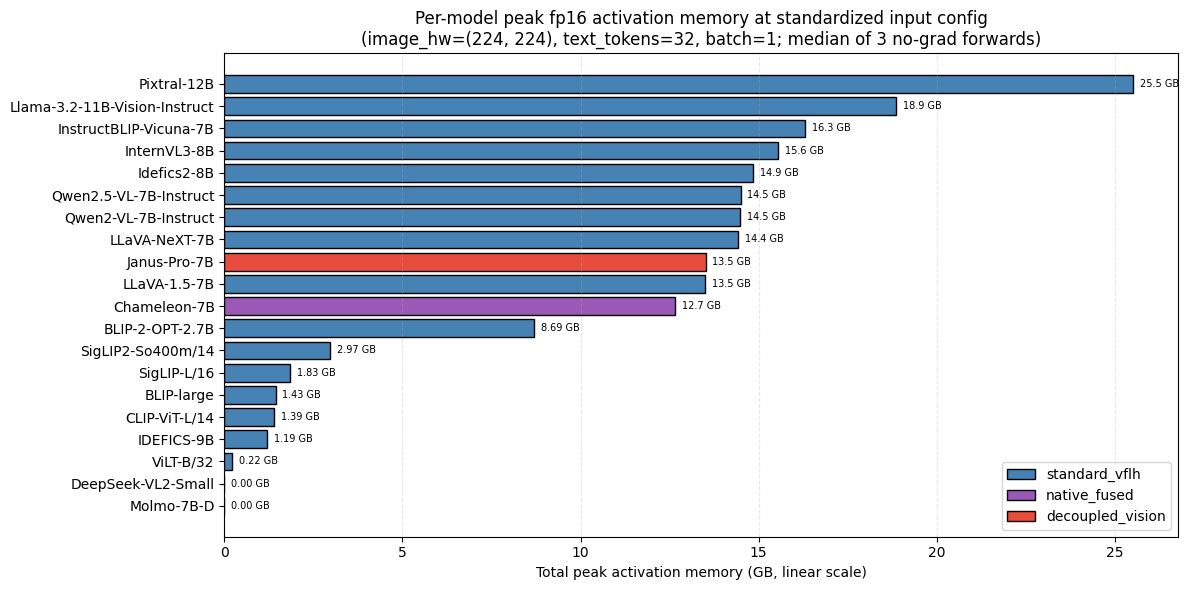

Saved to /workspace/code_active/outputs/figures/nb04_total_memory_bar.png


In [16]:
if results:
    plot_df = mem_df.copy().sort_values('total_mb').reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 6))
    schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
    bar_colors = [schema_colors.get(s, 'gray') for s in plot_df['schema']]
    bars = ax.barh(plot_df['name'], plot_df['total_mb'] / 1024, color=bar_colors, edgecolor='black')
    ax.set_xlabel('Total peak activation memory (GB, linear scale)')
    ax.set_title('Per-model peak fp16 activation memory at standardized input config\n'
                 f'(image_hw={ic.image_hw}, text_tokens={ic.text_tokens}, batch={ic.batch_size}; median of {MEMORY_REPEATS} no-grad forwards)')
    for bar, val in zip(bars, plot_df['total_mb'] / 1024):
        label = f'{val:.2f} GB' if val < 10 else f'{val:.1f} GB'
        ax.annotate(label, xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points', va='center', fontsize=7)
    from matplotlib.patches import Patch
    legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
    ax.legend(handles=legend_handles, loc='lower right')
    ax.grid(True, axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb04_total_memory_bar.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb04_total_memory_bar.png"}')

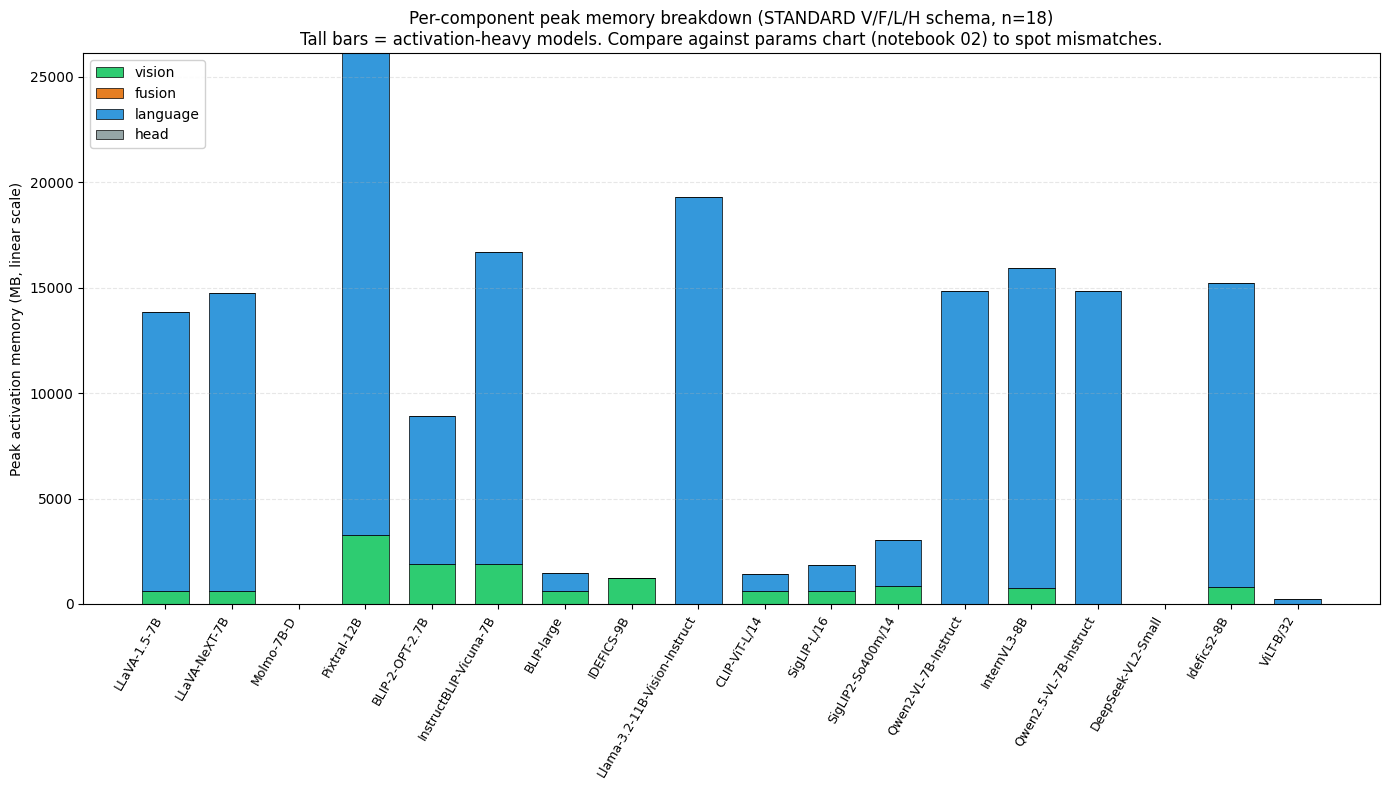

Saved to /workspace/code_active/outputs/figures/nb04_stacked_vflh_memory.png


In [17]:
if results:
    # Stacked bar V/F/L/H memory per STANDARD-schema model
    sb_df = mem_df[mem_df['schema'] == 'standard_vflh'].copy().sort_values(['family', 'year', 'name']).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 8))
    x = np.arange(len(sb_df))
    width = 0.7
    colors = {'vision': '#2ECC71', 'fusion': '#E67E22', 'language': '#3498DB', 'head': '#95A5A6'}
    bottoms = np.zeros(len(sb_df))
    for cname in ['vision', 'fusion', 'language', 'head']:
        col = f'{cname}_mem_mb'
        if col not in sb_df.columns:
            continue
        vals = sb_df[col].fillna(0).values
        ax.bar(x, vals, width=width, bottom=bottoms, color=colors[cname], edgecolor='black', linewidth=0.5, label=cname)
        bottoms += vals
    ax.set_xticks(x)
    ax.set_xticklabels(sb_df['name'], rotation=60, ha='right', fontsize=9)
    ax.set_ylabel('Peak activation memory (MB, linear scale)')
    ax.set_title('Per-component peak memory breakdown (STANDARD V/F/L/H schema, n={})\n'.format(len(sb_df)) +
                 'Tall bars = activation-heavy models. Compare against params chart (notebook 02) to spot mismatches.')
    ax.legend(loc='upper left', framealpha=0.9)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb04_stacked_vflh_memory.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb04_stacked_vflh_memory.png"}')

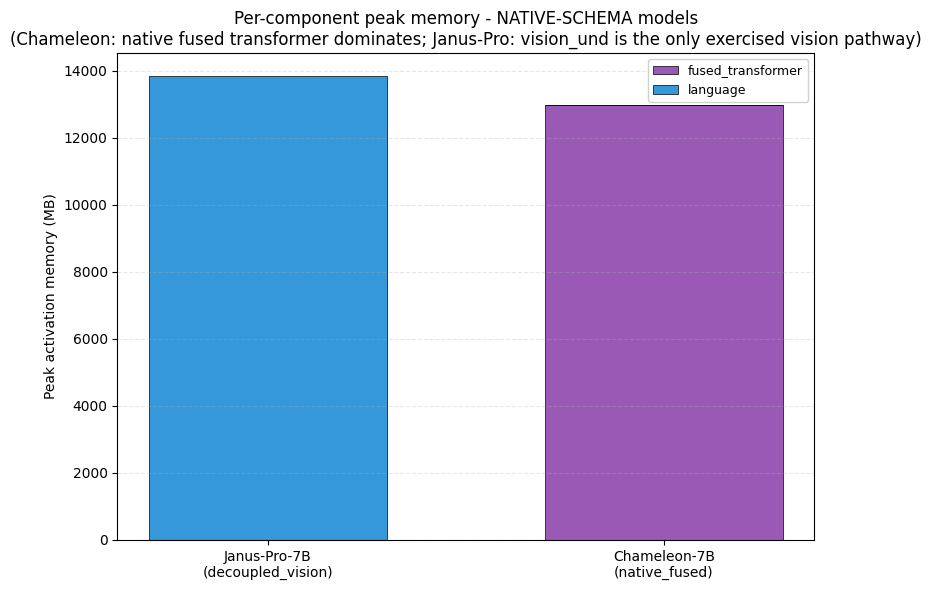

Saved to /workspace/code_active/outputs/figures/nb04_stacked_native_memory.png


In [18]:
if results:
    # Stacked bar for NATIVE-schema models - chameleon + janus
    native_df = mem_df[mem_df['schema'].isin(['native_fused', 'decoupled_vision'])].copy().sort_values(['schema', 'name']).reset_index(drop=True)
    if len(native_df) == 0:
        print('No native-schema models in the result set.')
    else:
        fig, ax = plt.subplots(figsize=(8, 6))
        x = np.arange(len(native_df))
        width = 0.6
        native_palette = {
            'fused_transformer': '#9B59B6',
            'vision_und':        '#1ABC9C',
            'vision_gen':        '#16A085',
            'embeddings':        '#F39C12',
            'fusion':            '#E67E22',
            'language':          '#3498DB',
            'head':              '#95A5A6',
            'vision':            '#2ECC71',
        }
        bottoms = np.zeros(len(native_df))
        for cname in ['fused_transformer', 'vision', 'vision_und', 'vision_gen', 'embeddings', 'fusion', 'language', 'head']:
            col = f'{cname}_mem_mb'
            if col not in native_df.columns:
                continue
            vals = native_df[col].fillna(0).values
            if vals.sum() == 0:
                continue
            ax.bar(x, vals, width=width, bottom=bottoms, color=native_palette.get(cname, 'gray'), edgecolor='black', linewidth=0.5, label=cname)
            bottoms += vals
        ax.set_xticks(x)
        ax.set_xticklabels([f'{n}\n({s})' for n, s in zip(native_df['name'], native_df['schema'])], fontsize=10)
        ax.set_ylabel('Peak activation memory (MB)')
        ax.set_title('Per-component peak memory - NATIVE-SCHEMA models\n'
                     '(Chameleon: native fused transformer dominates; Janus-Pro: vision_und is the only exercised vision pathway)')
        ax.legend(loc='upper right', framealpha=0.9, fontsize=9)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb04_stacked_native_memory.png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved to {FIG_DIR / "nb04_stacked_native_memory.png"}')

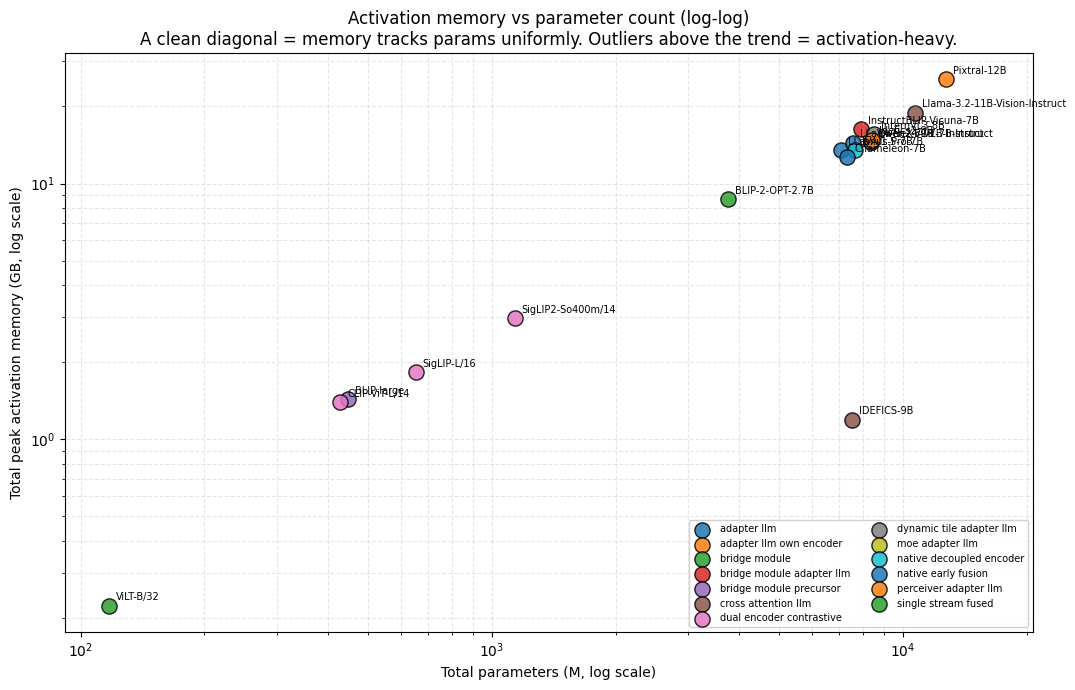

Saved to /workspace/code_active/outputs/figures/nb04_memory_vs_params_scatter.png


In [19]:
# Memory vs params scatter (reads nb02 output if present)
if results:
    nb02_csv = MEASUREMENT_DIR / 'nb02_parameter_summary.csv'
    if nb02_csv.exists():
        params_df_ext = pd.read_csv(nb02_csv)
        merged = params_df_ext.merge(mem_df[['name', 'total_mb', 'schema']], on='name', how='inner', suffixes=('', '_mem'))
        if 'schema' not in merged.columns and 'schema_mem' in merged.columns:
            merged['schema'] = merged['schema_mem']
        fig, ax = plt.subplots(figsize=(11, 7))
        families = sorted(merged['family'].unique())
        cmap = plt.get_cmap('tab10')
        for i, fam in enumerate(families):
            d = merged[merged['family'] == fam]
            ax.scatter(d['total_M'], d['total_mb'] / 1024, s=120, color=cmap(i % 10), edgecolor='black', alpha=0.85, label=fam.replace('_', ' '))
            for _, row in d.iterrows():
                ax.annotate(row['name'], (row['total_M'], row['total_mb'] / 1024),
                            xytext=(5, 4), textcoords='offset points', fontsize=7)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Total parameters (M, log scale)')
        ax.set_ylabel('Total peak activation memory (GB, log scale)')
        ax.set_title('Activation memory vs parameter count (log-log)\n'
                     'A clean diagonal = memory tracks params uniformly. Outliers above the trend = activation-heavy.')
        ax.legend(loc='lower right', fontsize=7, framealpha=0.9, ncol=2)
        ax.grid(True, which='both', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb04_memory_vs_params_scatter.png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved to {FIG_DIR / "nb04_memory_vs_params_scatter.png"}')
    else:
        print('Skipping memory-vs-params scatter (nb02_parameter_summary.csv not found - run notebook 02 first).')

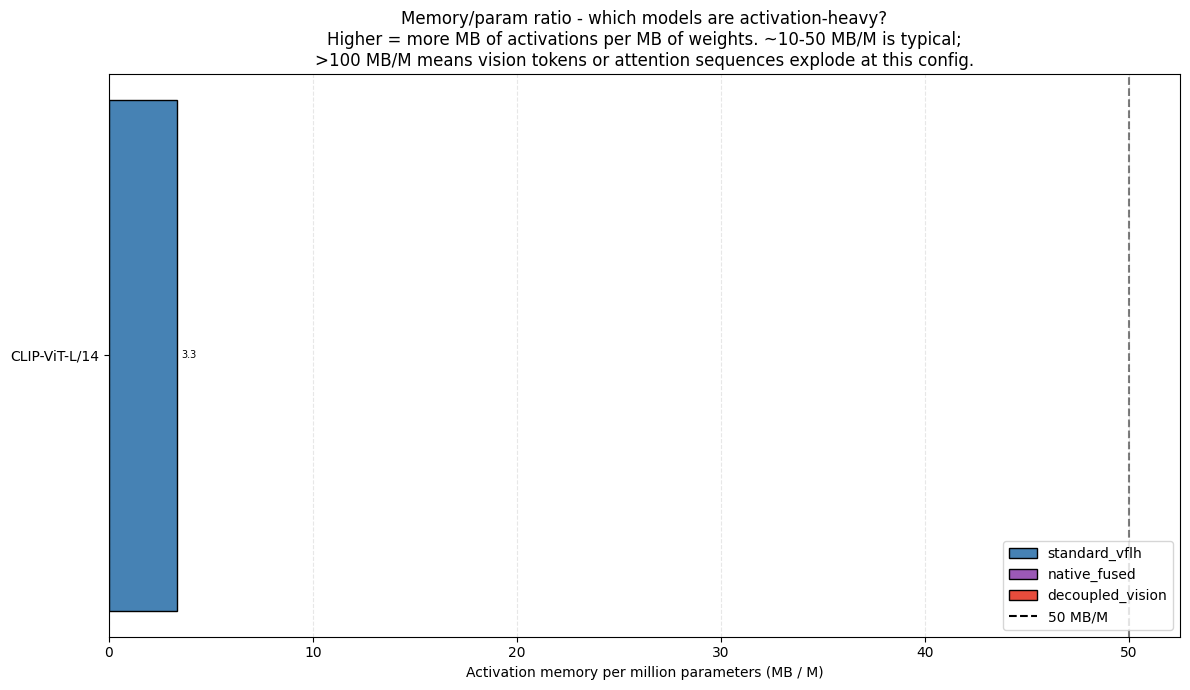

Saved to /workspace/code_active/outputs/figures/nb04_mem_per_param_bar.png


In [20]:
# Memory / param ratio bar - exposes activation-heavy models
if results and 'mem_per_param_MB_per_M' in mem_df.columns:
    rdf = mem_df.dropna(subset=['mem_per_param_MB_per_M']).copy()
    rdf = rdf[rdf['mem_per_param_MB_per_M'] > 0].sort_values('mem_per_param_MB_per_M')
    if len(rdf) == 0:
        print('No mem/param ratios available (nb02 must run first to populate params columns).')
    else:
        fig, ax = plt.subplots(figsize=(12, 7))
        schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
        bar_colors = [schema_colors.get(s, 'gray') for s in rdf['schema']]
        bars = ax.barh(rdf['name'], rdf['mem_per_param_MB_per_M'], color=bar_colors, edgecolor='black')
        ax.set_xlabel('Activation memory per million parameters (MB / M)')
        ax.set_title('Memory/param ratio - which models are activation-heavy?\n'
                     'Higher = more MB of activations per MB of weights. ~10-50 MB/M is typical;\n'
                     '>100 MB/M means vision tokens or attention sequences explode at this config.')
        ax.axvline(50, color='black', linestyle='--', alpha=0.5, label='50 MB/M (typical upper end)')
        for bar, val in zip(bars, rdf['mem_per_param_MB_per_M']):
            ax.annotate(f'{val:.1f}', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                        xytext=(3, 0), textcoords='offset points', va='center', fontsize=7)
        from matplotlib.patches import Patch
        legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
        legend_handles.append(plt.Line2D([0], [0], color='black', linestyle='--', label='50 MB/M'))
        ax.legend(handles=legend_handles, loc='lower right')
        ax.grid(True, axis='x', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb04_mem_per_param_bar.png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved to {FIG_DIR / "nb04_mem_per_param_bar.png"}')

---
## 10. Per-family summary statistics

Aggregate by family — mean memory total and mean memory-per-param, n per family. A high mean mem-per-param flags an activation-dominated family.

In [21]:
if results:
    family_summary = mem_df.groupby('family').agg(
        n_models           = ('name', 'count'),
        mean_total_mb      = ('total_mb', 'mean'),
        mean_total_GB      = ('total_GB', 'mean'),
        mean_vision_like_mb= ('vision_like_mb', 'mean'),
        mean_language_mb   = ('language_like_mb', 'mean'),
        mean_v_to_l_ratio  = ('v_to_l_mem_ratio', 'mean'),
        mean_mem_per_param = ('mem_per_param_MB_per_M', 'mean'),
        models             = ('name', lambda s: ', '.join(s)),
    ).round(2).sort_values('mean_total_GB', ascending=False)
family_summary if results else None

,n_models,mean_total_mb,mean_total_GB,mean_vision_like_mb,mean_language_mb,mean_v_to_l_ratio,mean_mem_per_param,models
family,,,,,,,,
adapter_llm_own_encoder,1,26124.25,25.51,3250.16,22874.09,0.14,NaN,Pixtral-12B
bridge_module_adapter_llm,1,16705.32,16.31,1912.29,14793.03,0.13,NaN,InstructBLIP-Vicuna-7B
perceiver_adapter_llm,1,15215.04,14.86,824.22,14390.81,0.06,NaN,Idefics2-8B
dynamic_tile_adapter_llm,3,15203.76,14.85,253.55,14950.21,0.02,NaN,"Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, ..."
native_decoupled_encoder,1,13834.99,13.51,0.00,13834.99,0.00,NaN,Janus-Pro-7B
native_early_fusion,1,12965.04,12.66,0.00,12965.04,0.00,NaN,Chameleon-7B
cross_attention_llm,2,10264.90,10.02,609.83,9655.07,0.00,NaN,"IDEFICS-9B, Llama-3.2-11B-Vision-Instruct"
adapter_llm,3,9534.44,9.31,405.36,9129.08,0.04,NaN,"LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D"
bridge_module,1,8899.24,8.69,1912.29,6986.95,0.27,NaN,BLIP-2-OPT-2.7B


In [22]:
# Cross-family interpretation
if results:
    print('=== Family-level activation-memory patterns ===\n')
    print('Most memory-hungry families (by mean total GB):')
    for fam, row in family_summary.head(5).iterrows():
        print(f'  {fam:35s} mean = {row["mean_total_GB"]:.2f} GB  (n={int(row["n_models"])})')
    print('\nMost activation-heavy families (by mean mem/param ratio):')
    mpr = family_summary.dropna(subset=['mean_mem_per_param']).sort_values('mean_mem_per_param', ascending=False)
    for fam, row in mpr.head(5).iterrows():
        print(f'  {fam:35s} mean = {row["mean_mem_per_param"]:.1f} MB/M params  (n={int(row["n_models"])})')

=== Family-level activation-memory patterns ===

Most memory-hungry families (by mean total GB):
  adapter_llm_own_encoder             mean = 25.51 GB  (n=1)
  bridge_module_adapter_llm           mean = 16.31 GB  (n=1)
  perceiver_adapter_llm               mean = 14.86 GB  (n=1)
  dynamic_tile_adapter_llm            mean = 14.85 GB  (n=3)
  native_decoupled_encoder            mean = 13.51 GB  (n=1)

Most activation-heavy families (by mean mem/param ratio):
  dual_encoder_contrastive            mean = 3.3 MB/M params  (n=3)


---
## 11. Hardware footprint table — total VRAM needed at inference

The number a deployment engineer plans around. For each model at batch=1, the **minimum VRAM** to run inference is:

`min_vram = fp16_weights + peak_activation_memory + headroom`

where `headroom` is 1-2 GB for the CUDA context, kernel cache, and tokenizer/processor state. We use 1.5 GB as a conservative midpoint.

This table is what you cite in the paper's hardware-requirements section. For batch>1, multiply the activation column by approximately the batch size (transformer activations scale ~linearly with batch).

In [23]:
if results:
    HEADROOM_GB = 1.5
    hw_df = mem_df[['name', 'family', 'schema', 'fp16_GB', 'total_mb']].copy()
    hw_df['activations_GB'] = (hw_df['total_mb'] / 1024).round(2)
    hw_df['headroom_GB'] = HEADROOM_GB
    hw_df['min_vram_GB'] = (hw_df['fp16_GB'] + hw_df['activations_GB'] + HEADROOM_GB).round(2)
    # Recommend a GPU class
    def gpu_recommendation(mv):
        if mv <= 8:   return 'T4 (16GB) / RTX-4060 OK'
        if mv <= 16:  return 'L4 / A10G / RTX-4090 (24GB)'
        if mv <= 24:  return 'L4 / A10G (24GB) tight; prefer L40'
        if mv <= 40:  return 'A100-40GB / L40 (48GB)'
        if mv <= 80:  return 'A100-80GB / H100-80GB'
        return '> 80 GB - need 2x A100-80GB'
    hw_df['recommended_gpu'] = hw_df['min_vram_GB'].apply(gpu_recommendation)
    hw_df = hw_df.sort_values('min_vram_GB').reset_index(drop=True)
    hw_df[['name', 'family', 'schema', 'fp16_GB', 'activations_GB', 'headroom_GB', 'min_vram_GB', 'recommended_gpu']]

**Reading the hardware footprint table:**
* `fp16_GB` is the weights footprint at fp16 (from the model spec).
* `activations_GB` is the measured peak from this notebook (sum across components).
* `headroom_GB` is the 1.5 GB safety margin.
* `min_vram_GB` is the floor. If your GPU has less than this, the forward will OOM.
* `recommended_gpu` is a rough sizing for batch=1 inference. For training, multiply activations by 4 (forward + backward + optimizer state).

**Caveat:** these numbers are for batch=1 at the standardized input config (224x224, 32 tokens). Dynamic-tile models (Qwen2-VL, InternVL3) run at native 448x448 inside `dummy_inputs.py` — so their `activations_GB` is closer to deployment reality than the standardized number. Pixtral always runs at its native 1024x1024.

---
## 12. Failures (debugging)

If any model failed, the row appears here. Common causes for memory measurement specifically:
* **CUDA OOM** at fp16 — try `QUANTIZATION='int8'` (DeepSeek-VL2, Pixtral on smaller cards).
* **Per-pass forward TypeError** — the runner falls back to positional args; if both fail it logs and skips.
* **NaN/inf in the model output** — happens with `interpolate_pos_encoding=False` on a model pretrained at a non-224 resolution; the F-1 fix in `dummy_inputs.py` handles this.

Look at the corresponding log file in `../outputs/logs/<timestamp>_04_memory_analysis_nb__<that_model>.txt` for the full traceback.

In [24]:
if failures:
    failures_df = pd.DataFrame(failures)
    print(f'{len(failures)} failures:')
    failures_df
else:
    print('No failures - all models succeeded.')

No failures - all models succeeded.


---
## 13. Save the master memory table to disk

The per-model JSONs are already saved (incrementally merged by `run_full_audit`). We additionally save the aggregated DataFrame as CSV + the family summary + the hardware-footprint table.

In [25]:
if not results:
    print('Nothing to save - no successful results.')
else:
    csv_master = MEASUREMENT_DIR / 'nb04_memory_summary.csv'
    csv_family = MEASUREMENT_DIR / 'nb04_family_summary.csv'
    csv_hw = MEASUREMENT_DIR / 'nb04_hardware_footprint.csv'
    mem_df.to_csv(csv_master, index=False)
    family_summary.to_csv(csv_family)
    hw_df.to_csv(csv_hw, index=False)
    print(f'Saved: {csv_master}')
    print(f'Saved: {csv_family}')
    print(f'Saved: {csv_hw}')
    print(f'Per-model JSONs: {MEASUREMENT_DIR}/<hf_id>.json (peak_mem_mb merged in)')
    print(f'Verbose .txt logs: {LOG_DIR}/')
    print(f'Figures: {FIG_DIR}/nb04_*.png')

Saved: /workspace/code_active/outputs/measurements/nb04_memory_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb04_family_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb04_hardware_footprint.csv
Per-model JSONs: /workspace/code_active/outputs/measurements/<hf_id>.json (peak_mem_mb merged in)
Verbose .txt logs: /workspace/code_active/outputs/logs/
Figures: /workspace/code_active/outputs/figures/nb04_*.png


---
## Next steps

* If everything above looks right -> continue to **`05_token_counts.ipynb`** for fusion-boundary token analysis (CPU-only; no model load).
* If a model failed -> open `outputs/logs/<timestamp>_04_memory_analysis_nb__<that_model>.txt`. Common causes:
  * CUDA OOM -> `QUANTIZATION='int8'` for that model only
  * `interpolate_pos_encoding` not handled by a custom architecture -> check that the F-1 fix in `dummy_inputs.py` covers it
  * `trust_remote_code` denied for InternVL3 / Molmo / DeepSeek-VL2 / Janus-Pro -> check spec.requires_trust_remote_code = True
* If a memory number looks wrong (e.g. SigLIP `vision_mem_mb` = 0) -> open the per-model log and look for the forward-call exception. The most common cause is a positional-vs-kwargs mismatch on a custom architecture.
* If Chameleon's `fused_transformer_mem_mb` is suspiciously low -> the dummy input only has text (32 tokens) because there's no V/F/L split. To measure memory with image tokens interleaved, you'd need to inject image tokens into `input_ids` — that's notebook 10's territory.

*End of notebook 04 (verbose v3-style). Pipeline: 00 setup -> 02 params -> 03 FLOPs -> **04 memory** -> 05 tokens -> 06 master table.*